# LeNet MNIST: compact comparison edition

    **Learning outcomes:** prepare a reproducible dataset, inspect tensor shapes,
    train a classifier, select a checkpoint using validation data, and evaluate on
    a separate test set. All class names and plots in this edition are in English.

    Run cells from top to bottom. The first dataset/model download requires internet.
    CPU mode works; set `COURSE_SMOKE=1` before starting the kernel for a short pipeline check.
    A smoke-test score is not a measure of model quality.

In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "Select the Python 3.12 project kernel."
assert version('torch').split("+")[0] == '2.14.1', "Select the locked project environment."
print("Python:", sys.version.split()[0])
print('torch' + ":", version('torch'))
print("Run mode:", 'Default classroom training parameters')

Python: 3.12.12
torch: 2.14.1
Run mode: Default classroom training parameters


In [2]:
from pathlib import Path
import os
import sys

# Find the English course root without relying on a specific working directory.
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "COURSE_ROOT").is_file()), None)
if COURSE is None and (start / "english" / "COURSE_ROOT").is_file():
    COURSE = start / "english"
if COURSE is None:
    raise RuntimeError("Start Jupyter inside the project or the english directory.")
sys.path.insert(0, str(COURSE / "common"))
os.environ.setdefault("HF_HOME", str(COURSE / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(COURSE / "data" / "torch-cache"))

'E:\\deep-learning-lab\\english\\data\\torch-cache'

In [3]:
EXPERIMENT = "lenet-mnist-compact"

import random
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA = COURSE / "01-image-classification" / "data"
OUTPUT = COURSE / "01-image-classification" / "outputs" / EXPERIMENT
DATA.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
EPOCHS = 1 if SMOKE else 3
BATCH_SIZE = 32 if SMOKE else 64
print(f"Device: {DEVICE}; experiment: {EXPERIMENT}; smoke test: {SMOKE}")

Device: cpu; experiment: lenet-mnist-compact; smoke test: False


## 1. Prepare training, validation, and test data

        Keep the official test split untouched until final evaluation. Create validation
        data only from the training split. The fixed seed controls the split. A classroom
        run uses a subset to keep runtime manageable; increase limits for a fuller experiment.

In [4]:
CLASS_NAMES = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
CHANNELS, IMAGE_SIZE = 1, 28
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))])
full_train = datasets.MNIST(DATA, train=True, download=True, transform=transform)
test_set = datasets.MNIST(DATA, train=False, download=True, transform=transform)

val_size = len(full_train) // 10
train_set, val_set = random_split(full_train, [len(full_train) - val_size, val_size],
                                  generator=torch.Generator().manual_seed(SEED))
train_set = Subset(train_set, range(min(len(train_set), 64 if SMOKE else 4000)))
val_set = Subset(val_set, range(min(len(val_set), 32 if SMOKE else 1000)))
test_set = Subset(test_set, range(min(len(test_set), 32 if SMOKE else 1000)))

0.3%

0.7%

1.0%

1.3%

1.7%

...

95.4%

97.4%

99.4%

100.0%

100.0%

Batch shape: (64, 1, 28, 28) Label shape: (64,)
Split sizes: 4000 1000 1000


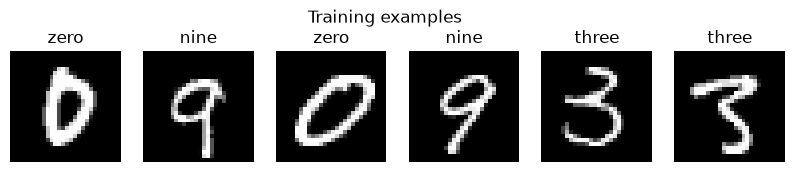

In [5]:
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, num_workers=0)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, num_workers=0)
images, labels = next(iter(train_loader))
print("Batch shape:", tuple(images.shape), "Label shape:", tuple(labels.shape))
print("Split sizes:", len(train_set), len(val_set), len(test_set))
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for axis, image, label in zip(axes, images, labels):
    view = image[0] if CHANNELS == 1 else image.permute(1, 2, 0)
    view = (view - view.min()) / (view.max() - view.min() + 1e-8)
    axis.imshow(view, cmap="gray" if CHANNELS == 1 else None)
    axis.set_title(CLASS_NAMES[int(label)])
    axis.axis("off")
fig.suptitle("Training examples")
plt.show()

## 2. Define the model

    A convolution learns local features with shared weights. Pooling reduces spatial
    size; the final linear layer returns one logit per class. Cross-entropy expects
    logits, so softmax is used only when displaying prediction probabilities.

In [6]:
class LeNet(nn.Module):
    def __init__(self, in_channels=1, image_size=28, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 6, kernel_size=5, padding=2), nn.ReLU(),
            nn.AvgPool2d(2), nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(),
            nn.AvgPool2d(2), nn.Flatten())
        with torch.no_grad():
            width = self.features(torch.zeros(1, in_channels, image_size, image_size)).shape[1]
        self.classifier = nn.Sequential(nn.Linear(width, 120), nn.ReLU(),
                                        nn.Linear(120, 84), nn.ReLU(),
                                        nn.Linear(84, num_classes))

    def forward(self, images):
        return self.classifier(self.features(images))

model = LeNet(CHANNELS, IMAGE_SIZE, len(CLASS_NAMES)).to(DEVICE)
print("Logit shape:", tuple(model(torch.zeros(2, CHANNELS, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)).shape))

Logit shape: (2, 10)


## 3. Train and select a checkpoint

    Training enables gradients and updates parameters. Evaluation disables gradients
    and switches dropout/batch normalization to evaluation behavior. Save the checkpoint
    with the highest validation accuracy; never choose it using test accuracy.

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=0.001)

def run_epoch(loader, training=False):
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            count += len(labels)
    return total_loss / count, correct / count

history, best_accuracy = [], -1.0
checkpoint = OUTPUT / "best_model.pt"
for epoch in range(EPOCHS):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(val_loader)
    history.append([train_loss, val_loss, train_accuracy, val_accuracy])
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        torch.save(model.state_dict(), checkpoint)
    print(f"Epoch {epoch + 1}/{EPOCHS} | train loss {train_loss:.4f} | "
          f"validation loss {val_loss:.4f} | validation accuracy {val_accuracy:.3f}")

Epoch 1/3 | train loss 1.3437 | validation loss 0.5953 | validation accuracy 0.789


Epoch 2/3 | train loss 0.5024 | validation loss 0.3776 | validation accuracy 0.891


Epoch 3/3 | train loss 0.3751 | validation loss 0.3217 | validation accuracy 0.900


## 4. Evaluate the saved checkpoint

Held-out test accuracy: 0.894


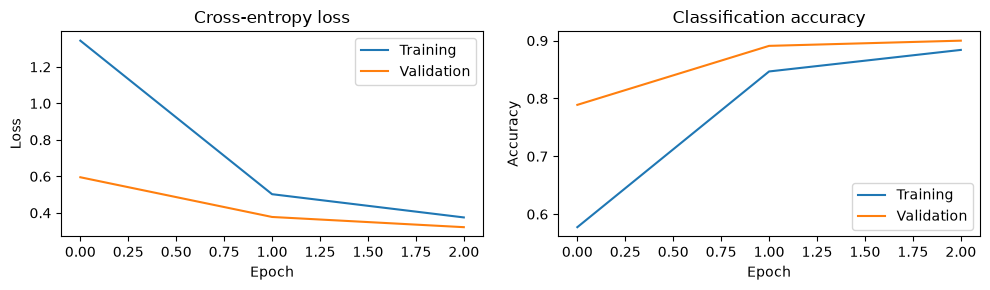

In [8]:
import json
model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
test_loss, test_accuracy = run_epoch(test_loader)
print(f"Held-out test accuracy: {test_accuracy:.3f}")
metrics = {"test_accuracy": test_accuracy, "test_loss": test_loss,
           "best_validation_accuracy": best_accuracy, "seed": SEED,
           "smoke_test": SMOKE, "epochs": EPOCHS, "classes": CLASS_NAMES}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
values = np.asarray(history)
axes[0].plot(values[:, 0], label="Training")
axes[0].plot(values[:, 1], label="Validation")
axes[0].set(title="Cross-entropy loss", xlabel="Epoch", ylabel="Loss")
axes[1].plot(values[:, 2], label="Training")
axes[1].plot(values[:, 3], label="Validation")
axes[1].set(title="Classification accuracy", xlabel="Epoch", ylabel="Accuracy")
for axis in axes:
    axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "training_curves.png")
plt.show()

## Exercises and discussion

    1. Predict each tensor shape before running the model.
    2. Compare learning rates while keeping the split fixed.
    3. Explain why validation and test results can differ.
    4. Inspect misclassified examples before increasing model size.
    5. For a new image, apply exactly the evaluation preprocessing and class mapping.

    The model weights, class names, seed, and metrics are stored under this experiment's
    output directory. Results depend on the subset, hardware, and training duration.